# Deal ya Doglapan? — Workshop notebook

**Data Science Club × AWS Club · Shark Tank India–style simulation**

Open in Colab or a Jupyter-compatible editor, select a Python 3 kernel, and choose **Run all**. The supplied CSV is embedded. The notebook uses NumPy, pandas, matplotlib and scikit-learn (1.2 or newer).

- **Part 1 · Prathamesh:** inspect, clean and engineer 13 pitch-time inputs, then prepare the train/test handoff.
- **Part 2 · Parth:** run Logistic Regression together, then reveal the Random Forest and Gradient Boosting results.

**Workshop question:** Does a pitch end in a deal that the founder accepts? The 1,000 pitches and measured results come from a simulated dataset.

The interactive pitch desk is in **Stage 5**. Run all cells to try a pitch or download the offline dashboard.

## 0. Setup

In [1]:
# Supplied 1,000-row CSV, gzip-compressed and encoded for a single-file notebook.
CSV_GZIP_BASE64 = (
    "..."
    "+ir+lVhphf8PqKK9MZGNAgA="
)

In [2]:
import base64
import gzip
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

csv_bytes = gzip.decompress(base64.b64decode(CSV_GZIP_BASE64))
df = pd.read_csv(BytesIO(csv_bytes))
print(f"Rows (pitches): {df.shape[0]}   Columns: {df.shape[1]}")
df[["Startup Name", "Industry", "Yearly Revenue", "Original Ask Amount",
    "Original Offered Equity", "Accepted Offer"]].head()

Rows (pitches): 1000   Columns: 32


,Startup Name,Industry,Yearly Revenue,Original Ask Amount,Original Offered Equity,Accepted Offer
0,AanganSpace,Lifestyle/Home,43.0,40.0,4.00,NaN
1,OfficePartners,Business Services,53.0,60.0,1.50,NaN
2,KesarFresh,Food and Beverage,NaN,200.0,1.00,1.0
3,SutraLabel,Beauty/Fashion,529.0,35.0,3.50,1.0
4,SutraWear,Beauty/Fashion,1368.0,90.0,1.25,1.0


🎯 **You are the Shark.** Look at the pitches above: *Deal or no deal?* What did **you** look at to decide? Revenue? The ask? The industry? Keep your answer in mind: by the end, we'll turn your gut feeling into columns a model can learn from.

💰 **Units:** money is in **₹ lakh** (100 lakh = ₹1 crore). Margins are in **% of revenue**.

# Phase 1 · The Problem: what exactly is a *Deal*?

In [3]:
print(df["Accepted Offer"].value_counts(dropna=False).rename({1.0: "1 = accepted", 0.0: "0 = rejected the offer"}))

Accepted Offer
1 = accepted              570
NaN                       357
0 = rejected the offer     73
Name: count, dtype: int64


Three kinds of pitches:
- **570** got an offer and **accepted** it → ✅ Deal
- **73** got an offer but **rejected** it (the Sharks' terms were too harsh) → ❌ No deal
- **357** are **blank**: the Sharks made **no offer**, so there was nothing to accept → ❌ No deal

So our target is simple: **Deal = 1 if the founder accepted an offer, else 0.** A blank here isn't "missing": it *means* something.

deal
Deal       570
No deal    430 

Deal rate: 57.0%


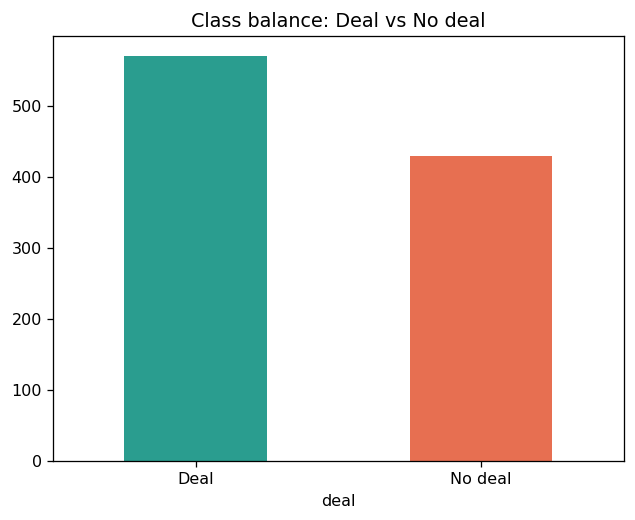

In [4]:
df["deal"] = (df["Accepted Offer"] == 1).astype(int)
counts = df["deal"].value_counts().rename({1: "Deal", 0: "No deal"})
print(counts.to_string(), f"\n\nDeal rate: {df['deal'].mean():.1%}")
counts.plot.bar(color=["#2a9d8f", "#e76f51"], rot=0, title="Class balance: Deal vs No deal"); plt.show()

train_ids, test_ids = train_test_split(
    df.index, test_size=0.2, stratify=df["deal"], random_state=42
)
eda_train = df.loc[train_ids]

**Class balance:** 57% Deal / 43% No Deal. An “Always Deal” model gives us a baseline for comparison.

We reserve 20% of the pitches now. The EDA can describe the archive's overall structure and data quality. Any exploration that compares clues against the deal outcome uses the training pitches only.

# Phase 2 · EDA (Exploratory Data Analysis)
## 2.1 The blank-cell trap

Rows if we simply delete every row with ANY blank cell: 64 out of 1000


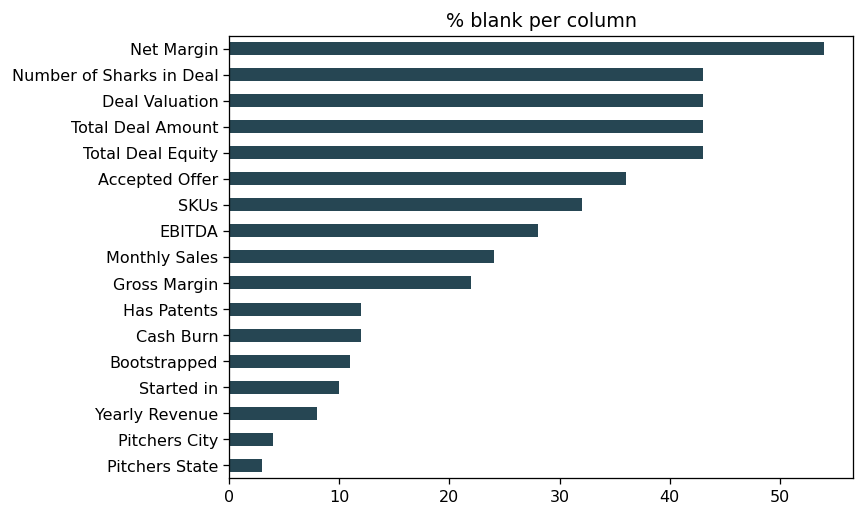

In [5]:
print("Rows if we simply delete every row with ANY blank cell:", len(df.dropna()), "out of", len(df))
blanks = (df.isna().mean() * 100).round(0)
blanks[blanks > 0].sort_values().plot.barh(color="#264653", figsize=(7, 5), title="% blank per column"); plt.show()

😱 **Only 64 of 1,000 rows survive!** Deleting blanks throws away 94% of our data. We'll have to **fill** blanks instead (Phase 6).

But first, a detective question: 🤔 *are the blanks random, or are founders hiding something?*

In [6]:
for col in ["SKUs", "EBITDA"]:
    blank = eda_train[col].isna()
    print(f"{col:6s} blank: {blank.sum():3d} pitches → deal rate {eda_train.loc[blank, 'deal'].mean():.0%}   |   "
          f"filled: deal rate {eda_train.loc[~blank, 'deal'].mean():.0%}")

SKUs   blank: 247 pitches → deal rate 55%   |   filled: deal rate 58%
EBITDA blank: 223 pitches → deal rate 39%   |   filled: deal rate 64%


In the training pitches, compare the deal rates for blank and recorded values. Check whether EBITDA disclosure has a bigger difference than SKU disclosure. A difference can make “EBITDA shared?” a useful clue in this simulation. The table alone cannot tell us why a value was left blank.

## 2.2 The cheating column (leakage)

In [7]:
rule = eda_train["Total Deal Amount"].notna().astype(int)   # "if a deal amount is written, predict Deal"
print(f"Accuracy of this one-line rule: {(rule == eda_train['deal']).mean():.0%}")

Accuracy of this one-line rule: 100%


🎉 **100% accurate!** Did we just solve Shark Tank?

…No. `Total Deal Amount` is only written **after** the Sharks say yes. When a new founder walks in, it doesn't exist yet. Using it is like reading the answer key during the exam. This is called **data leakage**.

**The time-machine test:** *"Would I know this column at the moment the founder starts pitching?"* If not, it can't be an input.

In [8]:
LEAKAGE = ["Received Offer", "Accepted Offer", "Total Deal Amount", "Total Deal Equity", "Deal Valuation", "Number of Sharks in Deal"]
print("Columns that fail the time-machine test:", LEAKAGE)

Columns that fail the time-machine test: ['Received Offer', 'Accepted Offer', 'Total Deal Amount', 'Total Deal Equity', 'Deal Valuation', 'Number of Sharks in Deal']


## 2.3 Detective work: numbers that can't be true

In [9]:
df[["Original Ask Amount", "Gross Margin", "Started in"]].describe().loc[["min", "50%", "max"]].round(1)

,Original Ask Amount,Gross Margin,Started in
min,15.0,5.0,1920.0
50%,70.0,58.0,2020.0
max,25000000.0,550.0,2201.0


🤔 Three things look wrong:
- Someone asked for **2,50,00,000 lakh** (that's ₹2.5 lakh crore, more than almost any company in India is worth!), while the typical ask is ₹70 lakh.
- A **Gross Margin of 550%**? You can't keep more than 100% of what you sell.
- A company **started in 2201**? That's a time traveller. And 1920 is suspicious too.

Let's investigate the asks. We know a rule from the show: **valuation = ask ÷ equity × 100**. Does the data obey it?

In [10]:
implied = df["Original Ask Amount"] / df["Original Offered Equity"] * 100
broken = (implied / df["Valuation Requested"]).round(2) != 1
print("Rows where valuation ≠ ask ÷ equity × 100:", broken.sum())
df.loc[broken, ["Startup Name", "Original Ask Amount", "Original Offered Equity", "Valuation Requested"]]

Rows where valuation ≠ ask ÷ equity × 100: 8


,Startup Name,Original Ask Amount,Original Offered Equity,Valuation Requested
162,TadkaSnacksGo,4500000.0,2.0,2250.00
263,PeakCamp,25000000.0,3.0,8333.33
314,SmartHubOne,4000000.0,2.0,2000.00
544,DesiKart,5000000.0,0.5,10000.00
664,ByteLabs,4500000.0,1.5,3000.00
882,DesiSnacksGo,17500000.0,3.0,5833.33
920,KisanGrow,6000000.0,3.5,1714.29
957,SuryaTechX,4500000.0,2.0,2250.00


Look at **ByteLabs**: an ask of **45,00,000** for 1.5% equity with a valuation of **3,000**. If the ask were **₹45 lakh**, then 45 ÷ 1.5 × 100 = **3,000** ✅. Someone typed the ask in **rupees** (45,00,000) instead of **lakh** (45). That's a **unit error**: the number is right, the unit is wrong.

The same idea explains the others: a margin of **550%** is really **55%** typed with an extra zero.

In [11]:
print("Gross Margin > 100%:", sorted(df.loc[df["Gross Margin"] > 100, "Gross Margin"].tolist()))
print("Impossible start years:", sorted(df.loc[~df["Started in"].between(1990, 2026) & df["Started in"].notna(), "Started in"].tolist()))

Gross Margin > 100%: [380.0, 410.0, 460.0, 500.0, 540.0, 550.0]
Impossible start years: [1920.0, 2091.0, 2109.0, 2201.0]


## 2.4 Outlier ≠ error

Mean revenue  : ₹658 lakh
Median revenue: ₹188 lakh
Top 5 revenues (₹ lakh): [18000.0, 25000.0, 32000.0, 41000.0, 52000.0]


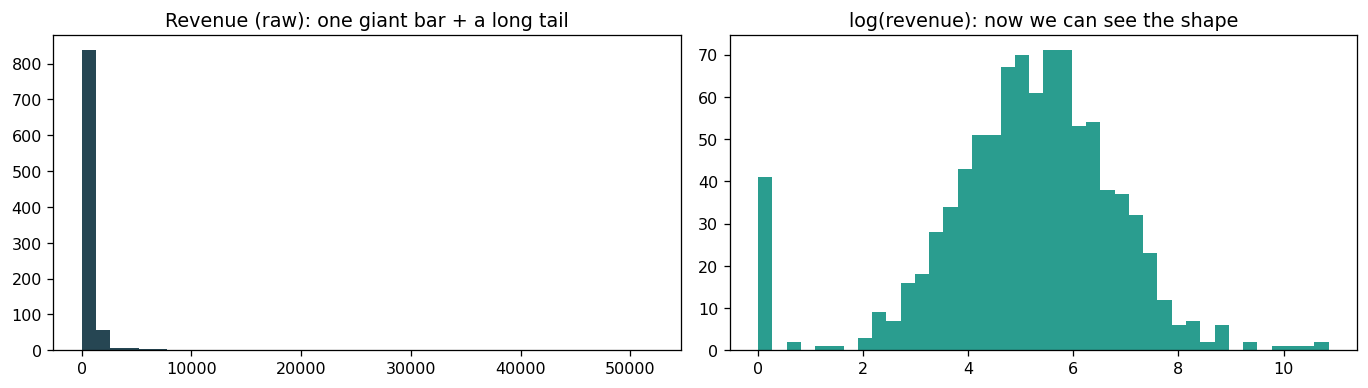

In [12]:
rev = df["Yearly Revenue"]
print(f"Mean revenue  : ₹{rev.mean():,.0f} lakh")
print(f"Median revenue: ₹{rev.median():,.0f} lakh")
print("Top 5 revenues (₹ lakh):", sorted(rev.nlargest(5).tolist()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(rev.dropna(), bins=40, color="#264653"); ax[0].set_title("Revenue (raw): one giant bar + a long tail")
ax[1].hist(np.log1p(rev.dropna()), bins=40, color="#2a9d8f"); ax[1].set_title("log(revenue): now we can see the shape")
plt.tight_layout(); plt.show()

A few companies make **₹180–520 crore** a year. Are these errors too? 🤔 **No!** Unlike a 550% margin, these numbers are *possible*: some big brands do come on the show. So we **keep** them.

But they cause two problems:
1. **The average lies.** One ₹520 Cr company drags the mean far above the median. It's like Ambani walking into a chai tapri: suddenly the "average income" in the room is in crores. The **median** (middle value) stays honest.
2. **The chart is squashed.** Taking the **log** shrinks huge numbers: ₹10 L, ₹100 L and ₹1,000 L become evenly spaced. Now we can see the real shape.

**Lesson 2: an error is fixed; a real outlier is kept and tamed with a log.**

# Phase 3 · Cleaning

In [13]:
clean = df.copy()
clean.loc[broken, "Original Ask Amount"] /= 100000                 # rupees → lakh
clean.loc[clean["Gross Margin"] > 100, "Gross Margin"] /= 10       # 550 → 55
clean.loc[~clean["Started in"].between(1990, 2026), "Started in"] = np.nan   # time travellers → blank (filled later)

check = (clean["Original Ask Amount"] / clean["Original Offered Equity"] * 100 / clean["Valuation Requested"]).round(2) != 1
print("Broken asks left:", check.sum(), "| Margins > 100% left:", (clean["Gross Margin"] > 100).sum(),
      "| Max ask now: ₹", clean["Original Ask Amount"].max(), "lakh")
print(f"Rows: {len(df)} → {len(clean)} (we fixed rows instead of deleting them)")

Broken asks left: 0 | Margins > 100% left: 0 | Max ask now: ₹ 500.0 lakh
Rows: 1000 → 1000 (we fixed rows instead of deleting them)


Cleaning done: target defined, leakage identified, unit errors fixed, impossible values blanked, real outliers kept. Now the fun part: **think like a Shark**.

# Phase 4 · Feature Engineering: think like a Shark
🤔 A founder asks **₹50 lakh for 5%**, and their company makes **₹1 crore a year**. What are they *really* claiming?

In [14]:
ask, equity, revenue = 50, 5, 100
valuation = ask / equity * 100
print(f"₹{ask} lakh for {equity}%  →  company worth ₹{valuation / 100:.0f} Cr")
print(f"Revenue ₹{revenue / 100:.0f} Cr  →  they want {valuation / revenue:.0f}× their yearly revenue")

₹50 lakh for 5%  →  company worth ₹10 Cr
Revenue ₹1 Cr  →  they want 10× their yearly revenue


That number, **valuation ÷ revenue** (the *multiple*), is exactly what Sharks calculate in their heads: *"You want 10 times your sales? Justify it!"* Does the data agree?

        rate  pitches
≤5×     0.86      147
5–10×   0.69      135
10–20×  0.60      179
20–30×  0.50       70
30–60×  0.37       98
>60×    0.05       74


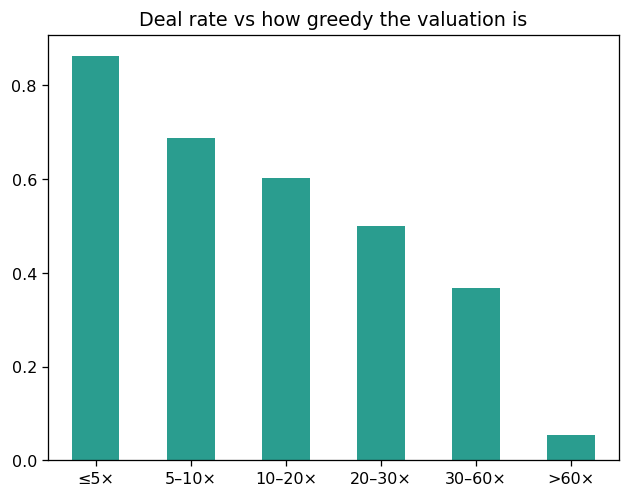

In [15]:
has_rev = clean["Yearly Revenue"] > 0
multiple = clean["Valuation Requested"] / clean["Yearly Revenue"].where(has_rev)
buckets = pd.cut(multiple, [0, 5, 10, 20, 30, 60, np.inf], labels=["≤5×", "5–10×", "10–20×", "20–30×", "30–60×", ">60×"])
by_mult = clean.loc[train_ids].groupby(buckets.loc[train_ids], observed=True)["deal"].agg(rate="mean", pitches="count")
print(by_mult.round(2))
by_mult["rate"].plot.bar(color="#2a9d8f", rot=0, title="Deal rate vs how greedy the valuation is"); plt.show()

Compare the first and last bars. The valuation-to-revenue multiple gives the model a way to express the Sharks' question about whether the asking valuation is high relative to sales.

In [16]:
training_clean = clean.loc[train_ids]
profit = np.select([training_clean["EBITDA"] > 0, training_clean["EBITDA"] <= 0], ["profitable", "loss-making"], "not shared")
print(training_clean.groupby(profit)["deal"].agg(rate="mean", pitches="count").round(2), "\n")
gm_q = pd.qcut(training_clean["Gross Margin"], 4, labels=["lowest 25%", "low-mid", "mid-high", "highest 25%"])
print("Deal rate by Gross Margin:\n", training_clean.groupby(gm_q, observed=True)["deal"].mean().round(2).to_string())

             rate  pitches
loss-making  0.38       64
not shared   0.39      223
profitable   0.67      513 

Deal rate by Gross Margin:
 Gross Margin
lowest 25%     0.39
low-mid        0.56
mid-high       0.71
highest 25%    0.73


Compare deal rates for profitable, loss-making and undisclosed cases, then compare the four gross-margin groups. Treat these differences as associations within the training pitches.

In [17]:
DEEP_TECH = ["Technology/Software", "Medical/Health", "Manufacturing", "Vehicles/Electrical Vehicles",
             "Green/CleanTech", "Agriculture", "Electronics"]
kind = np.where(training_clean["Industry"].isin(DEEP_TECH), "deep-tech", "consumer brand")
pd.crosstab(kind, training_clean["Has Patents"], values=training_clean["deal"], aggfunc="mean").round(2)

Has Patents,no,yes
row_0,,
consumer brand,0.57,0.50
deep-tech,0.53,0.73


**Do patents help?** Read the difference within each row of the table. When the relationship with patents differs by industry group, we call it an **interaction**. We give the model a “patent AND deep-tech” clue to represent that relationship.

In [18]:
city = training_clean.groupby("Pitchers City")["deal"].agg(rate="mean", pitches="count").sort_values("rate")
print("Lowest:\n", city.head(3).round(2).to_string(), "\n\nHighest:\n", city.tail(3).round(2).to_string())

Lowest:
                rate  pitches
Pitchers City               
Nagpur         0.40        5
Chandigarh     0.43        7
Ludhiana       0.43        7 

Highest:
                rate  pitches
Pitchers City               
Surat          0.77       13
Vadodara       0.82       11
Patna          1.00        1


Read the city names alongside their pitch counts. A handful of pitches can create a very high or low deal rate by chance. City is excluded from this feature set.

In [19]:
pairs = [("Monthly Sales", "Yearly Revenue"), ("Net Margin", "EBITDA")]
for a, b in pairs:
    print(f"{a} vs {b}: correlation {clean[[a, b]].corr(method='spearman').iloc[0, 1]:.2f}")

Monthly Sales vs Yearly Revenue: correlation 0.92
Net Margin vs EBITDA: correlation 0.92


**Monthly Sales** is basically Yearly Revenue ÷ 12, and **Net Margin** is EBITDA minus interest and tax. Correlation **0.92**: they tell the model the *same story twice*. They also have more blanks (24% and 54%). So we keep **one from each pair**: Yearly Revenue and EBITDA. Same information, fewer blanks.

**Lesson 4: more columns ≠ more information.**

Now we turn everything we learned into the model's input columns:

In [20]:
X = pd.DataFrame(index=clean.index)
# the ask: log shrinks huge numbers (Lesson 2)
X["log_ask"]        = np.log1p(clean["Original Ask Amount"])
X["equity_pct"]     = clean["Original Offered Equity"]
# traction and greed
X["log_revenue"]    = np.log1p(clean["Yearly Revenue"])                    # blank if not shared
X["log_multiple"]   = np.log(clean["Valuation Requested"] / clean["Yearly Revenue"].where(has_rev))   # blank if no revenue (can't divide by 0)
# money health
X["gross_margin"]   = clean["Gross Margin"]
X["ebitda"]         = clean["EBITDA"]
X["ebitda_shared"]  = clean["EBITDA"].notna().astype(int)                  # a blank can be a clue (Lesson 1)
X["cash_burn"]      = clean["Cash Burn"].map({"yes": 1, "no": 0})
# moat and founders
X["has_patents"]     = clean["Has Patents"].map({"yes": 1, "no": 0})
X["patent_deeptech"] = (X["has_patents"].fillna(0) * clean["Industry"].isin(DEEP_TECH)).astype(int)   # interaction
X["bootstrapped"]    = clean["Bootstrapped"].map({"yes": 1, "funded": 0})
X["company_age"]     = (2021 + clean["Season Number"]) - clean["Started in"]   # Season 1 aired in 2021-22
# industry: text for now
X["industry"] = clean["Industry"]
y = clean["deal"]
print(f"Features: {X.shape[1]} columns (from {df.shape[1] - 1} raw columns) | Rows: {X.shape[0]}")
X.head()

Features: 13 columns (from 32 raw columns) | Rows: 1000


,log_ask,equity_pct,log_revenue,log_multiple,gross_margin,ebitda,ebitda_shared,cash_burn,has_patents,patent_deeptech,bootstrapped,company_age,industry
0,3.713572,4.00,3.784190,3.146555,57.0,1.4,1,0.0,0.0,0,1.0,NaN,Lifestyle/Home
1,4.110874,1.50,3.988984,4.323758,52.0,12.9,1,0.0,0.0,0,0.0,4.0,Business Services
2,5.303305,1.00,NaN,NaN,33.0,NaN,0,1.0,1.0,0,1.0,NaN,Food and Beverage
3,3.583519,3.50,6.272877,0.636767,59.0,7.1,1,0.0,0.0,0,1.0,5.0,Beauty/Fashion
4,4.510860,1.25,7.221836,1.660731,77.0,14.0,1,0.0,0.0,0,0.0,5.0,Beauty/Fashion


**Our 13 features**, each with a reason:

| Feature | Why a Shark cares |
|---|---|
| `log_ask`, `equity_pct` | the deal on the table |
| `log_revenue` | traction: are customers paying? |
| `log_multiple` ✨ | greed: valuation ÷ revenue |
| `gross_margin`, `ebitda` | is the business healthy? |
| `ebitda_shared` ✨ | hiding numbers is a red flag |
| `cash_burn` | burning money every month? |
| `has_patents`, `patent_deeptech` ✨ | is the idea protected, and does it matter here? |
| `bootstrapped` | built with their own money? |
| `company_age` ✨ | how long they've survived |
| `industry` | Sharks have favourite sectors |

✨ = a new column we **engineered** (made ourselves).

**Not used, and why:**

| Columns | Reason |
|---|---|
| Received/Accepted Offer, Total Deal Amount/Equity, Deal Valuation, Number of Sharks in Deal | ⛔ leakage (only known after the pitch) |
| Valuation Requested | already inside `log_ask`, `equity_pct`, and `log_multiple` (it's just ask ÷ equity × 100) |
| Monthly Sales, Net Margin | repeat Yearly Revenue and EBITDA (Lesson 4) |
| Pitchers City, State | small groups, luck (Lesson 3) |
| Startup Name, Business Description, Pitch/Episode Number | names and IDs, not business facts |
| Presenters, gender, age group, SKUs, Season | no link to deals in our EDA |

# Phase 5 · Train/Test Split: the sealed exam

In [21]:
X_train, X_test = X.loc[train_ids], X.loc[test_ids]
y_train, y_test = y.loc[train_ids], y.loc[test_ids]
assert X_train.index.intersection(X_test.index).empty
print(f"Train (study material): {len(X_train)} rows")
print(f"Test  (sealed exam)   : {len(X_test)} rows")

Train (study material): 800 rows
Test  (sealed exam)   : 200 rows


The split made before outcome-based EDA is carried forward by row ID. Stratification preserves the class mix. Part 2 will use five training folds to compare the models, then evaluate on the sealed 200 pitches.

# Phase 6 · Preprocessing: make the data model-ready

🤔 Three problems are left: (1) some features have **blanks**, (2) industry is **text**, (3) numbers live on **very different scales**.

In [22]:
print("Blanks per feature (train):"); print(X_train.isna().sum()[lambda s: s > 0].to_string())
print(f"\nRanges: gross_margin {X_train['gross_margin'].min():.0f}–{X_train['gross_margin'].max():.0f} | "
      f"company_age {X_train['company_age'].min():.0f}–{X_train['company_age'].max():.0f} | has_patents 0–1")

Blanks per feature (train):
log_revenue      65
log_multiple     97
gross_margin    173
ebitda          223
cash_burn        93
has_patents      99
bootstrapped     81
company_age      88

Ranges: gross_margin 5–92 | company_age 0–15 | has_patents 0–1


- **Blanks → fill (imputation):** replace a missing value with the **median**, the typical value. We *can't* just delete rows (remember: only 64 survive!). For the EBITDA blanks we already saved the clue in `ebitda_shared`.
- **Text → numbers (one-hot encoding):** `industry = "Medical/Health"` becomes a column `Medical/Health = 1`, others 0. Industries with fewer than 20 pitches are grouped as *"other"* (small groups lie!).
- **Different scales → same scale (standardising):** gross margin goes up to 92, has_patents only to 1. Scaling puts every number around 0, so no column shouts louder just because its numbers are bigger.

⚠️ The preprocessor **learns from the training data only** (the medians, the scales). If it peeked at the test set, the exam wouldn't be sealed anymore.

In [23]:
NUM = [c for c in X.columns if c != "industry"]
CAT = ["industry"]
preprocessor = ColumnTransformer([
    ("numbers", Pipeline([("fill_blanks", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUM),
    ("industry", OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist", sparse_output=False), CAT),
])
demo = clone(preprocessor).fit(X_train)  # Demonstration fit, using training only
Xt_train = demo.transform(X_train)
print(f"Before preprocessing: {X_train.shape[1]} columns  →  after: {Xt_train.shape[1]} columns")
print("Blanks left:", int(np.isnan(Xt_train).sum()))
print("Industry columns created:", [n.replace("industry__industry_", "") for n in demo.get_feature_names_out() if n.startswith("industry__")])

Before preprocessing: 13 columns  →  after: 24 columns
Blanks left: 0
Industry columns created: ['Beauty/Fashion', 'Business Services', 'Children/Education', 'Fitness/Sports/Outdoors', 'Food and Beverage', 'Green/CleanTech', 'Lifestyle/Home', 'Manufacturing', 'Medical/Health', 'Technology/Software', 'Vehicles/Electrical Vehicles', 'infrequent_sklearn']


No blanks, everything is numeric, and everything is on a fair scale. ✅

# 🤝 Handoff to Part 2 (Model Training)

In [24]:
handoff = {
    "X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test,
    "preprocessor": preprocessor,
    "numeric_features": NUM, "categorical_features": CAT,
}
print(f"Handoff: {len(X_train)} train / {len(X_test)} test rows, {X.shape[1]} features")
print("Training baseline: Always Deal =", f"{y_train.mean():.1%}")

Handoff: 800 train / 200 test rows, 13 features
Training baseline: Always Deal = 57.0%


### Recap

We defined the verdict, excluded outcome columns, repaired the simulated unit errors, built pitch-time features, and handed off the original split with an unfitted preprocessing recipe. Each model learns its own imputation, encoding and scaling inside its training pipeline.

# Part 2 · Parth | Train your deal predictor

| Minutes | What happens |
|---|---|
| 0–3 | Ask the room to vote on a ₹50 lakh for 5% pitch. Explain Deal / No Deal and the Always Deal baseline. |
| 3–9 | **Everyone runs Logistic Regression.** Explain the probability curve, then change the decision threshold once. |
| 9–14 | **Facilitator reveals Random Forest and Gradient Boosting.** Explain voting and successive corrections with the pictures. |
| 14–20 | Reveal the scorecard. Find the CV winner and ask the room to read two kinds of mistakes from its confusion matrix. |

In a live session, start from the handoff with Part 1 already run. The facilitator can run the full notebook once ahead of time so the result figures are also available as saved outputs.

### Stage 1 · Three ways to reach a verdict

Start with the left panel. Save the two tree panels for the reveal. All three illustrations are simplified examples.

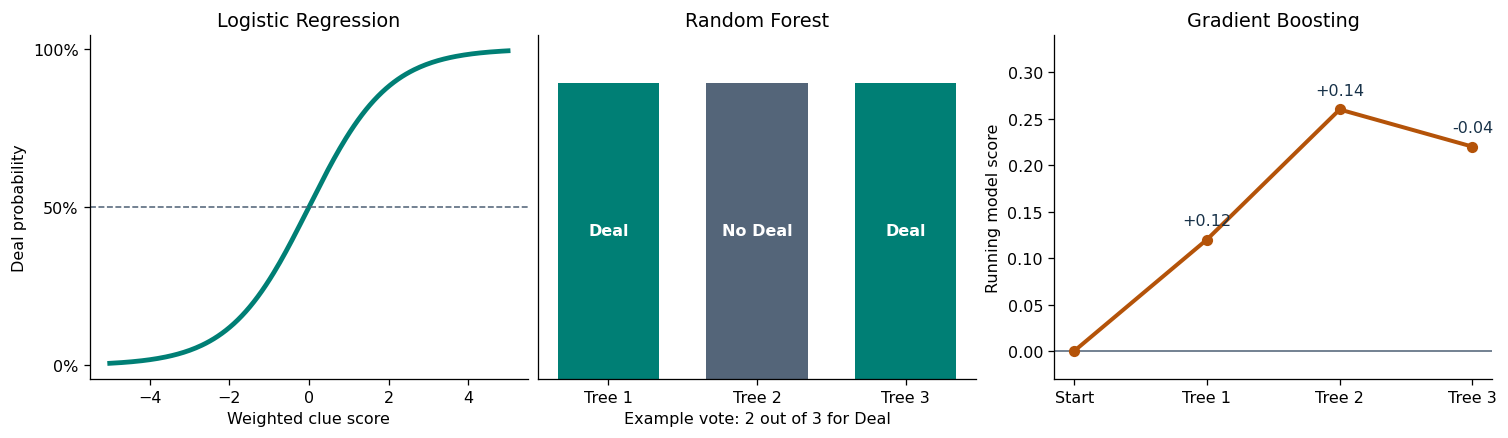

In [25]:
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate

navy, teal, orange, muted = "#183249", "#007f75", "#b45309", "#546579"
fig, (ax_log, ax_rf, ax_gb) = plt.subplots(1, 3, figsize=(13, 3.7), layout="constrained")
score = np.linspace(-5, 5, 200)
ax_log.plot(score, 1 / (1 + np.exp(-score)), color=teal, lw=3)
ax_log.axhline(.5, color=muted, linestyle="--", lw=1)
ax_log.set(title="Logistic Regression", xlabel="Weighted clue score", ylabel="Deal probability",
           yticks=[0, .5, 1])
ax_log.set_yticklabels(["0%", "50%", "100%"])

votes = ["Deal", "No Deal", "Deal"]
ax_rf.bar(["Tree 1", "Tree 2", "Tree 3"], [1, 1, 1], color=[teal, muted, teal], width=.68)
for index, vote in enumerate(votes):
    ax_rf.text(index, .50, vote, ha="center", va="center", color="white", weight="bold")
ax_rf.set(title="Random Forest", xlabel="Example vote: 2 out of 3 for Deal", ylim=(0, 1.16), yticks=[])

totals = [0, .12, .26, .22]
ax_gb.axhline(0, color=muted, lw=1)
ax_gb.plot(range(4), totals, marker="o", lw=2.5, color=orange)
for step, change in enumerate(np.diff(totals), start=1):
    ax_gb.annotate(f"{change:+.2f}", (step, totals[step]), xytext=(0, 9),
                   textcoords="offset points", ha="center", color=navy)
ax_gb.set(title="Gradient Boosting", ylabel="Running model score", ylim=(-.03, .34),
          xticks=range(4), xticklabels=["Start", "Tree 1", "Tree 2", "Tree 3"])
for axis in (ax_log, ax_rf, ax_gb):
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

### Stage 2 · Run Logistic Regression together

Logistic Regression combines weighted clues and maps the score to a number between 0 and 1. The threshold turns that score into a verdict. Use one practice pitch from the training set to see those two steps.

In [26]:
X_train, y_train = handoff["X_train"], handoff["y_train"]
logistic = Pipeline([
    ("preprocess", clone(handoff["preprocessor"])),
    ("model", LogisticRegression(max_iter=1000)),
])
logistic.fit(X_train, y_train)

practice_pitch = X_train.iloc[[0]]
deal_probability = logistic.predict_proba(practice_pitch)[0, 1]
pitch = clean.loc[practice_pitch.index[0]]
print(f"{pitch['Industry']} pitch | Ask: ₹{pitch['Original Ask Amount']:g} lakh "
      f"for {pitch['Original Offered Equity']:g}% equity")
print(f"Practice-pitch deal probability: {deal_probability:.1%}")

Business Services pitch | Ask: ₹250 lakh for 0.75% equity
Practice-pitch deal probability: 84.7%


**Student activity.** Set the threshold below the displayed probability and run the next cell. Set it above the probability and run it again. Discuss what changed. You used the same pitch and trained model both times.

In [27]:
threshold = 0.50  # Try a value below, then above, the displayed probability
verdict = "Deal" if deal_probability >= threshold else "No Deal"
print(f"Probability {deal_probability:.1%} | threshold {threshold:.0%} | verdict: {verdict}")

Probability 84.7% | threshold 50% | verdict: Deal


### Stage 3 · Reveal the two tree models

- **Random Forest:** many trees see different samples and consider different clues. In the sketch they cast votes. In this implementation their class probabilities are averaged.
- **Gradient Boosting:** trees are added one at a time to improve the current combined model. The running score can move up or down as a tree contributes a correction.

The next cell is for the facilitator. Each model uses the same stratified five folds of the 800 training pitches. We select by mean CV F1 for **Deal**, which balances precision and recall. The standard 50% cutoff is used for the comparison, independent of the student activity.

In [28]:
seed = 42
pipelines = {
    "Always Deal": Pipeline([
        ("preprocess", clone(handoff["preprocessor"])),
        ("model", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic Regression": logistic,
    "Random Forest": Pipeline([
        ("preprocess", clone(handoff["preprocessor"])),
        ("model", RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=seed)),
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocess", clone(handoff["preprocessor"])),
        ("model", GradientBoostingClassifier(max_depth=2, random_state=seed)),
    ]),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
training_rows = []
for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=folds,
        scoring=("f1", "balanced_accuracy", "roc_auc"), error_score="raise",
    )
    training_rows.append({
        "Model": name,
        "CV Deal F1": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std(),
        "CV Balanced Acc.": scores["test_balanced_accuracy"].mean(),
        "CV ROC AUC": scores["test_roc_auc"].mean(),
    })
training_scores = pd.DataFrame(training_rows).set_index("Model")
winner = training_scores.drop(index="Always Deal")["CV Deal F1"].idxmax()
print(f"Selected on training-fold Deal F1: {winner}")

Selected on training-fold Deal F1: Logistic Regression


### Stage 4 · Open the sealed test set

**Accuracy** counts all correct verdicts. **Balanced accuracy** gives Deal and No Deal equal weight. **Deal F1** combines precision and recall for the Deal class. **ROC AUC** measures how well the scores rank Deal above No Deal across thresholds.

Ask the room to identify a missed Deal and a predicted Deal that was actually No Deal. Read the counts from the confusion matrix. The held-out numbers measure performance on simulated pitches.

In [29]:
X_test, y_test = handoff["X_test"], handoff["y_test"]
test_rows = []
predictions = {}
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    probability = pipeline.predict_proba(X_test)[:, 1]
    predictions[name] = predicted
    test_rows.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, predicted),
        "Test Balanced Acc.": balanced_accuracy_score(y_test, predicted),
        "Test Deal F1": f1_score(y_test, predicted, zero_division=0),
        "Test ROC AUC": roc_auc_score(y_test, probability),
    })

results = training_scores.join(pd.DataFrame(test_rows).set_index("Model"))
display(results.round(3))

,CV Deal F1,CV F1 Std,CV Balanced Acc.,CV ROC AUC,Test Accuracy,Test Balanced Acc.,Test Deal F1,Test ROC AUC
Model,,,,,,,,
Always Deal,0.726,0.002,0.500,0.500,0.570,0.500,0.726,0.500
Logistic Regression,0.794,0.022,0.756,0.839,0.790,0.774,0.828,0.840
Random Forest,0.789,0.027,0.736,0.818,0.770,0.758,0.807,0.839
Gradient Boosting,0.787,0.020,0.736,0.823,0.775,0.764,0.810,0.837


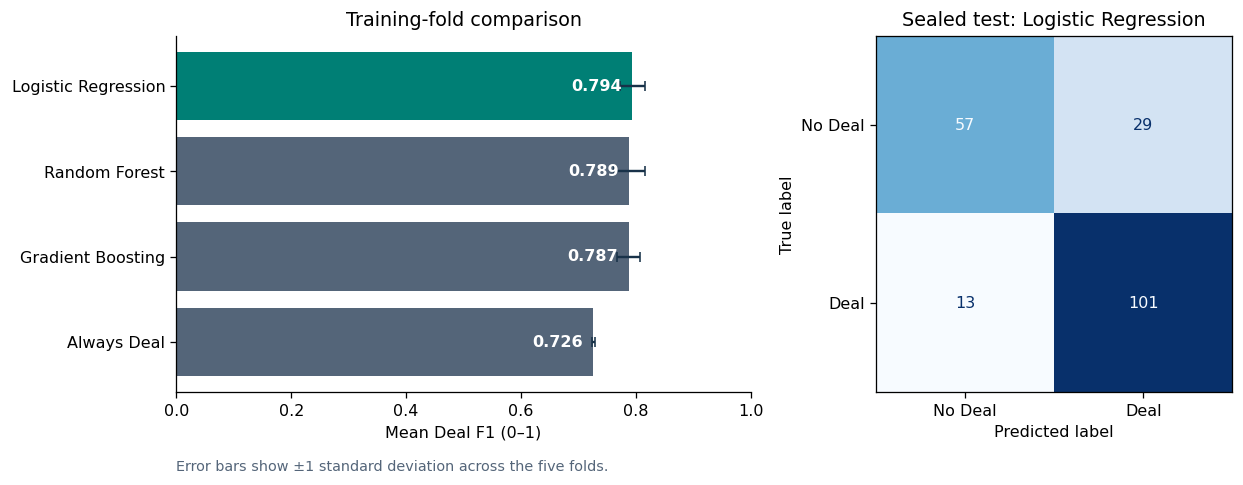

In [30]:
fig, (ax_rank, ax_matrix) = plt.subplots(1, 2, figsize=(11, 4.1),
                                        gridspec_kw={"width_ratios": [1.35, 1]},
                                        layout="constrained")
ordered = results["CV Deal F1"].sort_values(kind="stable")
colors = [teal if name == winner else muted for name in ordered.index]
bars = ax_rank.barh(ordered.index, ordered, color=colors, xerr=results.loc[ordered.index, "CV F1 Std"],
                     error_kw={"capsize": 3, "ecolor": navy})
ax_rank.set(title="Training-fold comparison", xlabel="Mean Deal F1 (0–1)", xlim=(0, 1))
for rect, value in zip(bars, ordered):
    ax_rank.text(value - .018, rect.get_y() + rect.get_height() / 2, f"{value:.3f}",
                 ha="right", va="center", color="white", weight="bold")
ax_rank.text(0, -.22, "Error bars show ±1 standard deviation across the five folds.",
             fontsize=9, color=muted, transform=ax_rank.transAxes)
ax_rank.spines[["top", "right"]].set_visible(False)

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[winner], labels=[0, 1], display_labels=["No Deal", "Deal"],
    cmap="Blues", colorbar=False, ax=ax_matrix,
)
ax_matrix.set_title(f"Sealed test: {winner}")
plt.show()

**Close with one question:** If a team wanted to catch more actual deals, which kinds of mistakes might increase when it lowers the threshold?

## Stage 5 — Interactive pitch desk
Run the cells below to open the dashboard here. Change the equity, submit the pitch, then click the photo to reveal the model score. Use **Model results** to compare the models. For a larger classroom view, open the generated `simulated_pitch_dashboard.html` in a browser. In Colab, you can download it from the Files panel.

**Presenter cue.** The pitch inputs are the detective’s clues. Changing the cutoff changes how much evidence the detective needs to call a Deal.

In [31]:
# Use the pipeline selected on the training folds and fitted in Stage 4.
from pathlib import Path
import json
from sklearn.metrics import confusion_matrix

selected = pipelines[winner]
prep = selected.named_steps["preprocess"]
estimator = selected.named_steps["model"]
numbers = prep.named_transformers_["numbers"]
scaler = numbers.named_steps["scale"]
encoder = prep.named_transformers_["industry"]
industries = sorted(X_train["industry"].dropna().unique().tolist())
encoded = encoder.transform(pd.DataFrame({"industry": industries}))

def export_tree(tree, classification=False):
    structure = tree.tree_
    values = structure.value[:, 0, :]
    leaf_value = values[:, 1] / values.sum(axis=1) if classification else values[:, 0]
    return dict(left=structure.children_left.tolist(), right=structure.children_right.tolist(),
                feature=structure.feature.tolist(), threshold=structure.threshold.tolist(),
                value=leaf_value.tolist())

if isinstance(estimator, LogisticRegression):
    model_data = dict(kind="logistic", weights=estimator.coef_[0].tolist(),
                      intercept=float(estimator.intercept_[0]))
elif isinstance(estimator, RandomForestClassifier):
    model_data = dict(kind="forest", trees=[export_tree(t, True) for t in estimator.estimators_])
elif isinstance(estimator, GradientBoostingClassifier):
    prior = estimator.init_.class_prior_
    model_data = dict(kind="boost", intercept=float(np.log(prior[1] / prior[0])),
                      rate=estimator.learning_rate,
                      trees=[export_tree(t) for t in estimator.estimators_[:, 0]])
else:
    raise TypeError(f"Unsupported estimator for dashboard: {type(estimator).__name__}")

dashboard_data = dict(
    winner=winner, model=model_data, numeric=NUM, industries=dict(zip(industries, encoded.tolist())),
    median=numbers.named_steps["fill_blanks"].statistics_.tolist(),
    mean=scaler.mean_.tolist(), scale=scaler.scale_.tolist(), deepTech=DEEP_TECH,
    train=len(X_train), test=len(X_test), matrix=confusion_matrix(y_test, predictions[winner], labels=[0,1]).tolist(),
    metrics=results[["CV Deal F1","Test Accuracy","Test Balanced Acc."]].to_dict("index"),
)

# Each industry's ask and equity axes use only the training pitches.
quantiles = np.linspace(0, 1, 9)
dashboard_data["boards"] = {
    name: {
        "asks": np.unique(np.expm1(np.quantile(group["log_ask"], quantiles)).round(6)).tolist(),
        "equities": np.unique(np.quantile(group["equity_pct"], quantiles).round(6)).tolist(),
    }
    for name, group in X_train.groupby("industry")
}


In [32]:
#@title Dashboard layout and embedded photos
# Run this cell once. The next cell connects it to the fitted model.
DASHBOARD_TEMPLATE = '<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Deal ya Doglapan? · Pitch desk</title>\n<style>\n*{box-sizing:border-box}body{margin:0;background:#f4f6f5;color:#17312f;font:16px/1.45 \'Segoe UI\',Arial,sans-serif}main{max-width:1160px;margin:auto;padding:22px clamp(14px,4vw,48px) 36px}header{background:#123631;color:white;padding:24px clamp(18px,4vw,44px);border-radius:16px}h1{font-size:clamp(30px,5vw,52px);letter-spacing:-.05em;line-height:1.05;margin:8px 0}header p{margin:6px 0;color:#c6e4d9}.club{font-weight:700;color:#a6e1ce}nav{display:flex;gap:6px;margin:18px 0}button{font:inherit;cursor:pointer}nav button,.submit{border:0;border-radius:8px;font-weight:650;padding:10px 18px}nav button{background:#e3ebe7;color:#284440}nav button[aria-pressed=true],.submit{background:#155a4e;color:white}button:focus-visible,input:focus-visible,select:focus-visible,summary:focus-visible{outline:3px solid #cb8422;outline-offset:2px}.layout{display:grid;grid-template-columns:1.08fr 1fr;gap:18px;align-items:start}.panel{background:white;padding:clamp(16px,3vw,25px);border:1px solid #d7e1dd;border-radius:14px}h2,h3{margin:0 0 10px;letter-spacing:-.025em}h2{font-size:25px}h3{font-size:17px}.fields{display:grid;grid-template-columns:1fr 1fr;gap:12px}.wide{grid-column:1/-1}label{display:block;font-weight:600;font-size:14px}input,select{display:block;width:100%;margin-top:5px;padding:10px;border:1px solid #99ada6;border-radius:6px;background:white;font:inherit;color:inherit}details{margin:16px 0}summary{cursor:pointer;font-weight:650}details .fields{padding-top:12px}.small{color:#546761;font-size:14px;margin:6px 0 12px}.reaction{display:block;position:relative;width:100%;min-height:220px;aspect-ratio:16/10;border-radius:10px;overflow:hidden;padding:0;background:#192826;border:0}.reaction img{position:absolute;inset:0;width:100%;height:100%;object-fit:cover;object-position:center 40%}.reaction span{position:absolute;bottom:8px;right:8px;padding:4px 11px;background:#142925ed;color:white;border-radius:12px;font-weight:650}.verdict{font-size:24px;font-weight:750;margin:0 0 8px}.score{padding:10px 12px;background:#e7f3ee;border-radius:8px}output{font-weight:700}input[type=range]{padding:0;accent-color:#155a4e}.history{margin:18px 0 0}.tablewrap{overflow:auto}table{width:100%;border-collapse:collapse;text-align:left}td,th{padding:8px;border-bottom:1px solid #d7e1dd;white-space:nowrap}th{font-size:13px;color:#48615a}ul{padding-left:20px}[hidden]{display:none!important}@media(max-width:700px){.layout{grid-template-columns:1fr}.panel{padding:16px}}@media(max-width:400px){.fields{grid-template-columns:1fr}}\n\n.reaction{width:80%;min-height:0;aspect-ratio:auto;margin:0 auto;background:#edf2ef;border:1px solid #d7e1dd;color:#17312f}\n.reaction img{position:static;display:block;width:100%;height:auto;aspect-ratio:16/10;object-fit:contain;object-position:center;background:#172a27}\n.reaction span{position:static;display:block;background:none;color:inherit;font-size:14px;padding:5px}\n#grid th{font-variant-numeric:tabular-nums;text-align:center}\n#grid td{padding:2px;border:0}\n#grid th[scope=row]{position:sticky;left:0;background:white;z-index:1}\n.tile{display:block;position:relative;width:100%;min-width:72px;height:64px;padding:0;background:#182c28;border:2px solid #af4149;border-radius:4px;overflow:hidden}\n.tile[data-deal=true]{border-color:#3978bf}.tile img{display:block;width:100%;height:100%;object-fit:contain}\n.tile[aria-pressed=true],.tile:focus-visible{outline:3px solid #17312f;outline-offset:-1px}\n.tile strong{position:absolute;inset:0;display:grid;place-items:center;color:white;background:#102722d9;font-size:18px}\n.confusion{max-width:540px;margin:10px 0 14px}.confusion th,.confusion td{text-align:center}.confusion td{font-size:20px;font-weight:700;background:#f7e7dc}.confusion .correct{background:#def1e8}\nheader{display:flex;align-items:center;gap:clamp(10px,2vw,22px)}.brand-logo{width:clamp(52px,8vw,92px);height:auto;flex:none}header>div{min-width:0}.pitch-actions{display:flex;flex-wrap:wrap;gap:8px;align-items:center}\n.submit:disabled{opacity:.65;cursor:wait}\n.audio-toggle{border:1px solid #99ada6;background:white;color:#155a4e;border-radius:8px;padding:9px 12px}\n.audio-toggle[aria-pressed=true]{background:#e7f3ee}\n.countdown{font-size:42px;font-weight:750;color:#155a4e;margin:0;font-variant-numeric:tabular-nums}\nnav{flex-wrap:wrap;align-items:center}\nnav #themeMusicToggle{margin-inline-start:auto}\n#themeMusicStatus:empty{display:none}\n</style><main>\n<header><img class="brand-logo" alt="Shark fin and rupee coin" src="..."><div><div class="club">Data Science Club × AWS Club</div><h1>Deal ya Doglapan?</h1><p>Pitch desk for simulated Shark Tank deals</p></div></header>\n<nav aria-label="Dashboard views"><button type="button" id="pitchTab" aria-pressed="true">Pitch desk</button><button type="button" id="evalTab" aria-pressed="false">Model results</button><button type="button" id="themeMusicToggle">Play theme music</button></nav>\n<p id="themeMusicStatus" class="small" role="status"></p>\n<audio id="themeMusic" src="..." loop preload="none"></audio>\n<section id="desk"><div class="layout"><form id="form" class="panel"><h2>Your pitch</h2><div class="fields">\n<label class="wide">Industry<select id="industry" required></select></label>\n<label>Ask (₹ lakh)<input id="ask" type="number" min="0.000001" step="any" placeholder="e.g. 50" required></label>\n<label>Equity offered (%)<input id="equity" type="number" min="0.000001" max="100" step="any" placeholder="e.g. 5" required></label>\n<label>Yearly revenue (₹ lakh)<input id="revenue" type="number" min="0" step="any" value="100"></label>\n<label>Gross margin (%)<input id="margin" type="number" max="100" step="any" placeholder="Undisclosed"></label></div>\n<details><summary>More pitch details</summary><div class="fields"><label>EBITDA (%)<input id="ebitda" type="number" step="any" placeholder="Undisclosed"></label><label>Company age (years)<input id="age" type="number" min="0" step="1" placeholder="Undisclosed"></label><label>Cash burn<select id="burn"></select></label><label>Has patents<select id="patent"></select></label><label>Bootstrapped<select id="bootstrap"></select></label></div></details>\n<p id="valuation" class="small"></p><div class="pitch-actions"><button id="submitPitch" class="submit" type="submit">Pitch to the model</button><button id="pitchAudio" class="audio-toggle" type="button" aria-pressed="false" hidden>Hindi audio</button></div></form>\n<section class="panel" id="awaitPitch"><h2>Model verdict</h2><p id="pitchInstructions">Enter your ask and equity, then click <strong>Pitch to the model</strong> to see your result.</p>\n<p id="pitchCountdown" class="countdown" role="timer" hidden></p>\n<p id="pitchStatus" role="status"></p><p id="pitchError" role="alert"></p></section><section hidden data-result class="panel" aria-label="Pitch verdict"><h2>Model verdict</h2><div class="verdict" id="verdict" aria-live="polite"></div><button class="reaction" id="reveal" type="button" aria-expanded="false" aria-controls="score"><img id="photo" alt=""><span id="hint">Reveal score</span></button>\n<p id="score" class="score" hidden></p><label for="cut">Deal cutoff <output id="cutLabel">50%</output></label><input id="cut" type="range" min="0" max="100" value="50"><p class="small">At or above the cutoff, the verdict is Deal. Move it to try a different decision on the same pitch.</p></section></div>\n<section hidden data-result class="panel history"><h2>Ask × equity matrix</h2>\n<p class="small">Try a different ask or equity for the same business. The rows and columns span the training pitches in your selected industry. Click a photo to reveal the score and use those terms.</p>\n<div class="tablewrap" role="region" aria-label="Ask and equity combinations" tabindex="0"><table id="grid" aria-label="Model predictions by ask in lakh and offered equity"></table></div></section>\n<section hidden data-result class="panel history"><h3>Compare your last two pitches</h3><div class="tablewrap"><table><thead><tr><th>Attempt</th><th>Ask (₹ lakh)</th><th>Equity</th><th>Valuation (₹ lakh)</th><th>Verdict at submission</th></tr></thead><tbody id="history"></tbody></table></div></section></section>\n<section id="evaluation" class="panel" hidden><h2>Model results</h2><p id="cohort"></p><div class="tablewrap"><table><thead><tr><th>Model</th><th>Training-fold Deal F1</th><th>Test accuracy</th><th>Test balanced accuracy</th></tr></thead><tbody id="metrics"></tbody></table></div><h3 style="margin-top:22px">Where did the model get it wrong?</h3><div class="tablewrap"><table class="confusion" aria-label="Confusion matrix for the selected model on the test set"><thead><tr><th scope="col">Actual outcome</th><th scope="col">Predicted No Deal</th><th scope="col">Predicted Deal</th></tr></thead><tbody><tr><th scope="row">No Deal</th><td class="correct" id="tn"></td><td id="fp"></td></tr><tr><th scope="row">Deal</th><td id="fn"></td><td class="correct" id="tp"></td></tr></tbody></table></div><p id="errors"></p><p class="small">These results describe simulated pitches at the trained models’ default decision rule. The pitch desk cutoff only changes the interactive verdict.</p></section>\n</main><script type="application/json" id="payload">__DATA__</script><script id="inference">\nfunction pitchFeatures(p, deepTech) {\n  const valuation = p.ask * 100 / p.equity;\n  return {log_ask:Math.log1p(p.ask), equity_pct:p.equity,\n    log_revenue:p.revenue === null ? null : Math.log1p(p.revenue),\n    log_multiple:p.revenue > 0 ? Math.log(valuation / p.revenue) : null,\n    gross_margin:p.margin, ebitda:p.ebitda, ebitda_shared:Number(p.ebitda !== null),\n    cash_burn:p.burn, has_patents:p.patent, patent_deeptech:Number(p.patent === 1 && deepTech.includes(p.industry)),\n    bootstrapped:p.bootstrap, company_age:p.age, industry:p.industry};\n}\nfunction treeValue(tree, x) {\n  let i=0;\n  while(tree.left[i] !== -1) {\n    i=Math.fround(x[tree.feature[i]]) <= tree.threshold[i] ? tree.left[i] : tree.right[i];\n  }\n  return tree.value[i];\n}\nfunction scorePitch(data, f) {\n  const x=data.numeric.map((key,i)=>((f[key] ?? data.median[i])-data.mean[i])/data.scale[i]);\n  x.push(...data.industries[f.industry]);\n  const m=data.model;\n  if (m.kind === \'forest\') return m.trees.reduce((s,t)=>s+treeValue(t,x),0)/m.trees.length;\n  const logit=m.kind === \'logistic\' ? m.weights.reduce((s,w,i)=>s+w*x[i],m.intercept) :\n    m.trees.reduce((s,t)=>s+m.rate*treeValue(t,x),m.intercept);\n  return 1/(1+Math.exp(-logit));\n}\n</script><script>\nconst D=JSON.parse(document.getElementById(\'payload\').textContent);\nconst el=id=>document.getElementById(id);\nconst pct=v=>(100*v).toFixed(1)+\'%\';\nconst num=id=>el(id).value===\'\'?null:Number(el(id).value);\nconst money=v=>v.toLocaleString(\'en-IN\',{maximumFractionDigits:2});\nfor (const key of Object.keys(D.industries)) el(\'industry\').add(new Option(key,key));\nif(Object.hasOwn(D.industries,\'Food and Beverage\')) el(\'industry\').value=\'Food and Beverage\';\nfor (const key of [\'burn\',\'patent\',\'bootstrap\']) for (const [name,val] of [[\'Undisclosed\',\'\'],[\'Yes\',\'1\'],[\'No\',\'0\']]) el(key).add(new Option(name,val));\nfunction row(parent,values) {const tr=el(parent).insertRow();for(const v of values)tr.insertCell().textContent=v;}\nfor(const [name,r] of Object.entries(D.metrics)) row(\'metrics\',[name,pct(r[\'CV Deal F1\']),pct(r[\'Test Accuracy\']),pct(r[\'Test Balanced Acc.\'])]);\nel(\'cohort\').textContent=D.winner+\' was selected by Deal F1 across five training folds. \'+D.train+\' pitches for training · \'+D.test+\' unseen simulated pitches for testing.\';\nconst [[tn,fp],[fn,tp]]=D.matrix;\nfor(const [id,value] of Object.entries({tn,fp,fn,tp})) el(id).textContent=value;\nel(\'errors\').textContent=fp+\' no-deals were called Deal. \'+fn+\' deals were missed. The model correctly identified \'+tp+\' deals and \'+tn+\' no-deals.\';\nfunction tab(isPitch){el(\'desk\').hidden=!isPitch;el(\'evaluation\').hidden=isPitch;el(\'pitchTab\').setAttribute(\'aria-pressed\',isPitch);el(\'evalTab\').setAttribute(\'aria-pressed\',!isPitch);}\nel(\'pitchTab\').onclick=()=>tab(true);el(\'evalTab\').onclick=()=>tab(false);\nlet currentScore=0,attempts=0,revealed=false;\nfunction paint(){const cut=num(\'cut\')/100,deal=currentScore>=cut;el(\'cutLabel\').textContent=Math.round(100*cut)+\'%\';el(\'verdict\').textContent=deal?\'Deal\':\'Doglapan · No deal\';el(\'photo\').src=deal?D.photos.deal:D.photos.doglapan;el(\'photo\').alt=deal?\'Aman in blue · Hum bhi bana lenge\':\'Ashneer · Ye sab doglapan hai\';el(\'score\').textContent=\'Model score \'+pct(currentScore)+\' · Deal cutoff \'+Math.round(100*cut)+\'%\';el(\'score\').hidden=!revealed;el(\'hint\').textContent=revealed?\'Hide score\':\'Reveal score\';el(\'reveal\').setAttribute(\'aria-expanded\',revealed);}\nfunction readPitch(){const p={industry:el(\'industry\').value};for(const key of [\'ask\',\'equity\',\'revenue\',\'margin\',\'ebitda\',\'age\',\'burn\',\'patent\',\'bootstrap\'])p[key]=num(key);\nreturn p;}\nconst countdownLines=[\n  \'The sharks are analysing your pitch…\',\n  \'Reviewing the numbers…\',\n  \'Weighing the valuation…\',\n  \'The sharks are discussing…\',\n  \'The verdict is coming…\'\n];\nconst resultPanels=document.querySelectorAll(\'[data-result]\');\nconst pitchControls=el(\'form\').querySelectorAll(\'input, select, #submitPitch\');\nconst audioToggle=el(\'pitchAudio\');\nconst speech=window.speechSynthesis;\nlet pending=false;\n\nif (speech && \'SpeechSynthesisUtterance\' in window) {\n  audioToggle.hidden=false;\n  audioToggle.onclick=()=>{\n    const enabled=audioToggle.getAttribute(\'aria-pressed\')===\'true\';\n    audioToggle.setAttribute(\'aria-pressed\',!enabled);\n    if (enabled) speech.cancel();\n  };\n}\n\nfunction speakHindi(line) {\n  if (audioToggle.getAttribute(\'aria-pressed\')!==\'true\') return;\n  try {\n    speech.cancel();\n    const utterance=new SpeechSynthesisUtterance(line);\n    utterance.lang=\'hi-IN\';\n    const voice=speech.getVoices().find(voice=>/^hi(?:[-_]|$)/i.test(voice.lang));\n    if (voice) utterance.voice=voice;\n    speech.speak(utterance);\n  } catch (error) {\n    console.warn(\'Pitch audio is unavailable.\',error);\n  }\n}\n\nfunction waitForReveal() {\n  const deadline=performance.now()+5000;\n  const timer=el(\'pitchCountdown\');\n  timer.hidden=false;\n  return new Promise(resolve=>{\n    function tick() {\n      const remaining=deadline-performance.now();\n      if (remaining<=0) {\n        resolve();\n        return;\n      }\n      const seconds=Math.ceil(remaining/1000);\n      timer.textContent=seconds+\' s\';\n      el(\'pitchStatus\').textContent=countdownLines[5-seconds];\n      setTimeout(tick,remaining-(seconds-1)*1000);\n    }\n    tick();\n  });\n}\n\nasync function pitch(terms=null) {\n  if (pending || !el(\'form\').reportValidity()) return;\n  pending=true;\n  if (terms) {\n    el(\'ask\').value=terms.ask;\n    el(\'equity\').value=terms.equity;\n    valuePreview();\n  }\n  const p=readPitch();\n  selectedTerms=terms;\n  pitchControls.forEach(control=>{control.disabled=true;});\n  resultPanels.forEach(panel=>{panel.hidden=true;});\n  el(\'awaitPitch\').hidden=false;\n  el(\'pitchInstructions\').hidden=true;\n  el(\'pitchError\').textContent=\'\';\n  try {\n    speakHindi(\'शार्क्स आपकी पिच पर विचार कर रहे हैं।\');\n    await waitForReveal();\n    const score=scorePitch(D,pitchFeatures(p,D.deepTech));\n    if (!Number.isFinite(score)) throw new Error(\'Invalid model score\');\n    // Matrix validation needs the form controls enabled.\n    pitchControls.forEach(control=>{control.disabled=false;});\n    renderMatrix(true);\n    currentScore=score;\n    revealed=Boolean(terms);\n    paint();\n    const valuation=p.ask*100/p.equity;\n    row(\'history\',[++attempts,money(p.ask),p.equity+\'%\',money(valuation),el(\'verdict\').textContent+\' @ \'+el(\'cutLabel\').textContent]);\n    if (el(\'history\').rows.length>2) el(\'history\').deleteRow(0);\n    el(\'awaitPitch\').hidden=true;\n    resultPanels.forEach(panel=>{panel.hidden=false;});\n    if (!el(\'desk\').hidden) {\n      if (document.activeElement===document.body) {\n        const focusTarget=terms?el(\'grid\').querySelector(\'[aria-pressed=true]\'):el(\'submitPitch\');\n        focusTarget?.focus({preventScroll:true});\n      }\n      speakHindi(currentScore>=num(\'cut\')/100\n        ? \'इस बिज़नेस में दम है। डील पक्की!\'\n        : \'इस बार डील नहीं होगी।\');\n    }\n  } catch (error) {\n    el(\'pitchError\').textContent=\'The prediction could not be completed. Please pitch again.\';\n    console.error(\'Pitch prediction failed.\',error);\n  } finally {\n    el(\'pitchCountdown\').hidden=true;\n    el(\'pitchStatus\').textContent=\'\';\n    pitchControls.forEach(control=>{control.disabled=false;});\n    pending=false;\n  }\n}\nfunction valuePreview(){const ask=num(\'ask\'),eq=num(\'equity\');el(\'valuation\').textContent=ask>0&&eq>0?\'Implied valuation: ₹\'+money(ask*100/eq)+\' lakh\':\'\';}\nlet selectedTerms=null;\nfunction renderMatrix(newPitch=false) {\n  const grid=el(\'grid\');\n  grid.replaceChildren();\n  if ((!attempts && !newPitch) || !el(\'form\').checkValidity()) return;\n  const p=readPitch(), board=D.boards[p.industry], cutoff=num(\'cut\')/100;\n  function header(row,title,scope) {\n    const th=document.createElement(\'th\');\n    th.scope=scope; th.textContent=title; row.append(th);\n  }\n  const top=grid.createTHead().insertRow();\n  header(top,\'Equity / Ask (₹ lakh)\',\'col\');\n  board.asks.forEach(ask=>header(top,money(ask),\'col\'));\n  const body=grid.createTBody();\n  for (const equity of board.equities) {\n    const tr=body.insertRow();\n    header(tr,equity+\'%\',\'row\');\n    for (const ask of board.asks) {\n      const value=scorePitch(D,pitchFeatures({...p,ask,equity},D.deepTech));\n      const deal=value>=cutoff;\n      const chosen=selectedTerms?.ask===ask && selectedTerms?.equity===equity;\n      const btn=document.createElement(\'button\'), img=document.createElement(\'img\');\n      btn.type=\'button\'; btn.className=\'tile\'; btn.dataset.deal=deal;\n      btn.setAttribute(\'aria-pressed\',chosen);\n      btn.setAttribute(\'aria-label\',\'Ask \'+ask+\' lakh, equity \'+equity+\'%. \'+(deal?\'Deal\':\'No deal\')+\'. \'+(chosen?pct(value):\'Reveal score\'));\n      img.alt=\'\'; img.src=deal?D.photos.deal:D.photos.doglapan; btn.append(img);\n      if (chosen) {const label=document.createElement(\'strong\'); label.textContent=pct(value); btn.append(label);}\n      btn.onclick=()=>pitch({ask,equity});\n      tr.insertCell().append(btn);\n    }\n  }\n}\nel(\'form\').oninput=()=>{selectedTerms=null;valuePreview();renderMatrix();};\nel(\'form\').onsubmit=e=>{e.preventDefault();pitch();};\nel(\'cut\').oninput=()=>{paint();renderMatrix();};\nel(\'reveal\').onclick=()=>{revealed=!revealed;paint();};\nvaluePreview();\nconst themeMusic=el(\'themeMusic\');\nconst themeMusicToggle=el(\'themeMusicToggle\');\nconst themeMusicStatus=el(\'themeMusicStatus\');\nthemeMusic.volume=1;\n\nasync function playThemeMusic() {\n  try {\n    await themeMusic.play();\n  } catch (error) {\n    if (!themeMusic.paused || error.name===\'AbortError\') return;\n    themeMusicStatus.textContent=error.name===\'NotAllowedError\'\n      ? \'Select Play theme music to enable sound. Turn up your device volume if needed.\'\n      : \'Theme music could not play. Select Play theme music to retry.\';\n  }\n}\n\nthemeMusic.addEventListener(\'playing\',()=>{\n  themeMusicToggle.textContent=\'Pause theme music\';\n  themeMusicStatus.textContent=\'\';\n});\nthemeMusic.addEventListener(\'pause\',()=>{\n  themeMusicToggle.textContent=\'Play theme music\';\n});\nthemeMusicToggle.onclick=()=>{\n  if (themeMusic.paused) playThemeMusic();\n  else themeMusic.pause();\n};\nplayThemeMusic();\n</script></html>'
REACTION_PHOTOS = {'deal': '...', 'doglapan': ''}

Interactive pitch desk. Run this cell to activate it.
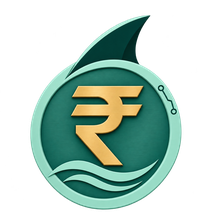
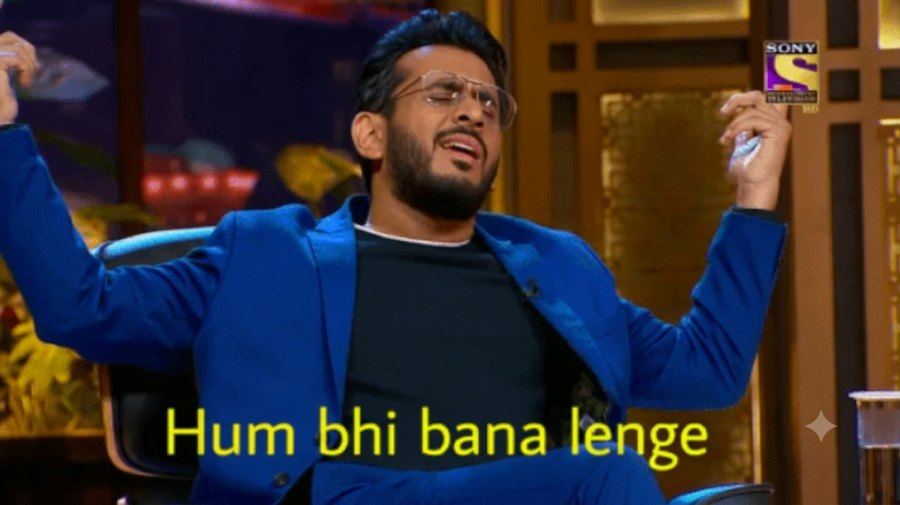
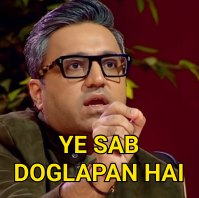

In [33]:
# Connect the interactive desk to the fitted model and its held-out evaluation.
from html import escape
from IPython.display import HTML, display

dashboard_data["photos"] = REACTION_PHOTOS
payload = json.dumps(dashboard_data, allow_nan=False, separators=(",", ":")).replace("<", r"\u003c")
dashboard_html = DASHBOARD_TEMPLATE.replace("__DATA__", payload)
dashboard_path = Path("simulated_pitch_dashboard.html")
dashboard_path.write_text(dashboard_html, encoding="utf-8")
print(f"Live model: {winner} | {len(X_train)} training pitches | {len(X_test)} test pitches")
print(f"Offline copy: {dashboard_path.resolve()}")
display(HTML('<iframe title="Interactive pitch desk" style="width:100%;height:900px;border:0" '
             'srcdoc="' + escape(dashboard_html, quote=True) + '"></iframe>'))